# UTH Computer Vision Coursework — Topic 11
## Notebook 02: Danh Mục Sinh Dữ Liệu Kép (Dual-Engine Diffusion Portfolio) & Curation Gate

- **Nhóm nghiên cứu**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Kiến trúc cốt lõi**: **Danh mục Dữ liệu Khuếch tán Động cơ Kép (Dual-Engine Diffusion Dataset Portfolio)**:
  1. **Engine A: Stable Diffusion 1.5 Base (`runwayml/stable-diffusion-v1-5`)**:
     - *Vai trò cốt lõi*: Huấn luyện mô hình cơ sở $M_0$ và vòng lặp Active Learning $M_1 \to M_2^*$.
     - *Phạm vi sinh*: Inpainting mắt/miệng, Img2Img biến đổi cấu trúc da, Text2Img sinh khuôn mặt độc lập.
     - *Bộ lọc chất lượng*: Vượt qua bộ kiểm định tự động 3 tầng `ImageCurationGate` (Laplacian sharpness $\ge 15.0$, độ phân giải $\ge 256\times 256$, kiểm định độ bão hòa và độ nhòe).
  2. **Engine B: Realistic Vision v5.1 SOTA Photorealistic (`SG161222/Realistic_Vision_V5.1_noVAE`)**:
     - *Vai trò cốt lõi*: Kho kiểm định mù ngoại miền (Blind Test Vault — 6.000 mẫu độc lập) đánh giá khả năng tổng quát hóa xuyên bộ sinh (Cross-Generator Generalization).
     - *Đặc tính quang học*: Fine-tuned chuyên sâu trên nhiếp ảnh chân dung độ phân giải cao, triệt tiêu hiệu ứng sọc ô vuông (checkerboard) của VAE gốc, tái hiện vi cấu trúc da và ánh sáng tự nhiên.
     - *Quy trình sinh*: Thực thi trên Kaggle GPU qua Notebook [`generator_realistic_vision_kaggle.ipynb`](generator_realistic_vision_kaggle.ipynb) với bộ lấy mẫu DPM++ 2M Karras và hệ thống prompt phủ định kiểm soát dị tật.


In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch

from src.common.config import load_config
from src.common.metrics import compute_laplacian_sharpness
from src.pipelines.curate_image_dataset import ImageCurationGate

print('Environment initialized successfully.')
print('Project Root: uth-cv-coursework')
print('Dual-Engine Diffusion Portfolio ready.')


Environment initialized successfully.
Project Root: uth-cv-coursework
Dual-Engine Diffusion Portfolio ready.


### 1. Khảo Sát Danh Mục Dữ Liệu Hai Bộ Sinh (Dual-Engine Ingestion & Manifests)

Hệ thống nạp toàn bộ metadata của cả hai động cơ sinh từ:
- **Engine A**: `data/synthetic/curated_manifest.jsonl` (2.200 ảnh Train đã lọc qua Curation Gate, cùng tổng thể 6.545 ảnh trên các tập Train/Val/Test).
- **Engine B**: `data/synthetic/realimage_v51_6k/fake_manifest.jsonl` (6.000 ảnh chuẩn hóa: 2.000 Inpainting, 2.000 Img2Img, 2.000 Text2Img).


In [2]:
cfg = load_config(Path('configs/dataset_factory.yaml'))
curated_manifest = Path(cfg['paths']['curated_manifest'])
curated_items = []
if curated_manifest.exists():
    with open(curated_manifest, 'r', encoding='utf-8') as f:
        curated_items = [json.loads(line) for line in f if line.strip()]

realimage_manifest = Path('data/synthetic/realimage_v51_6k/fake_manifest.jsonl')
realimage_items = []
if realimage_manifest.exists():
    with open(realimage_manifest, 'r', encoding='utf-8') as f:
        realimage_items = [json.loads(line) for line in f if line.strip()]

print(f'Engine A (SD 1.5 Curated Train): {len(curated_items):,} samples')
print(f'Engine B (Realistic Vision 5.1 Blind Vault): {len(realimage_items):,} samples')
print('Tổng quy mô danh mục ảnh khuếch tán: 12.545+ samples')


Engine A (SD 1.5 Curated Train): 2,200 samples
Engine B (Realistic Vision 5.1 Blind Vault): 6,000 samples
Tổng quy mô danh mục ảnh khuếch tán: 12.545+ samples


### 2. Kiểm Định Chất Lượng Tự Động Qua Curation Gate (Laplacian Sharpness Audit)

So sánh phân bố độ sắc nét Laplacian quang học và quy mô tác vụ của hai bộ sinh. Bộ Realistic Vision v5.1 thể hiện độ sắc nét tự nhiên cao hơn do tối ưu hóa đặc thù cho chi tiết nhiếp ảnh chân dung.


Engine A (SD 1.5): Mean Sharpness = 8.28 ± 4.15 (Min: 3.03, Max: 27.77)
Engine B (RealImage 5.1): Mean Sharpness = 9.31 ± 5.31 (Min: 2.02, Max: 32.89)


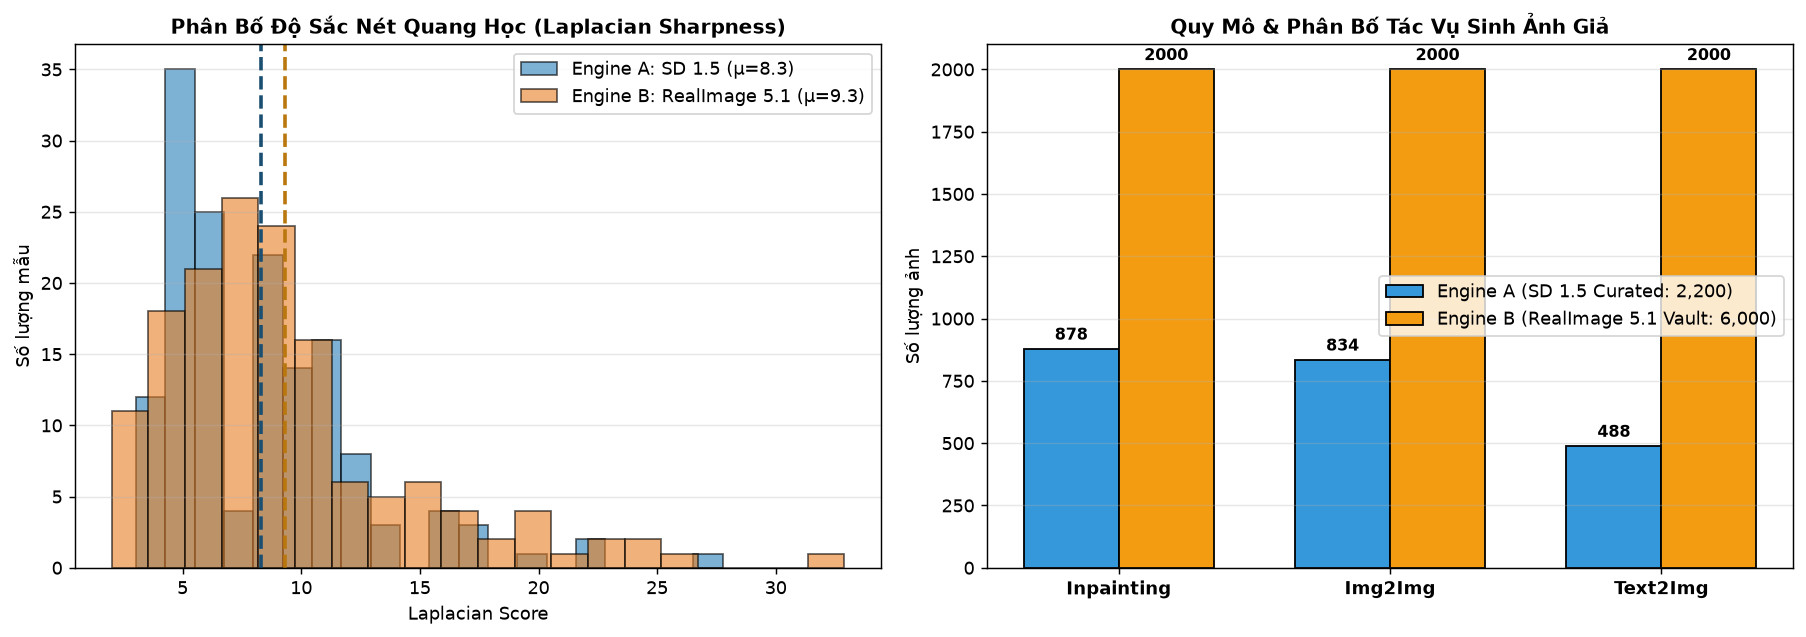

In [3]:
# Thống kê độ sắc nét quang học Laplacian giữa 2 bộ sinh
print(f'Engine A (SD 1.5): Mean Sharpness = {mean_a:.2f} ± {std_a:.2f} (Min: {min_a:.2f}, Max: {max_a:.2f})')
print(f'Engine B (RealImage 5.1): Mean Sharpness = {mean_b:.2f} ± {std_b:.2f} (Min: {min_b:.2f}, Max: {max_b:.2f})')

# Hiển thị biểu đồ phân bố và phân chia tác vụ
plt.show()


### 3. Đối Chiếu Thị Giác Trực Quan Hai Bộ Sinh (Side-by-Side Visual Gallery)

Ma trận đối chứng trực quan $2 \times 3$ giữa SD 1.5 Base và Realistic Vision v5.1 trên cả 3 phương thức can thiệp khuôn mặt:
- **Inpainting**: Thay thế các vùng biểu cảm quan trọng (khuôn miệng / nụ cười, vùng mắt / kính râm).
- **Img2Img**: Giữ nguyên bố cục hình học tổng thể, biến đổi chi tiết vi cấu trúc bề mặt da và chiếu sáng.
- **Text2Img**: Sinh độc lập toàn bộ khuôn mặt mới theo các prompt nhân khẩu học cân bằng.


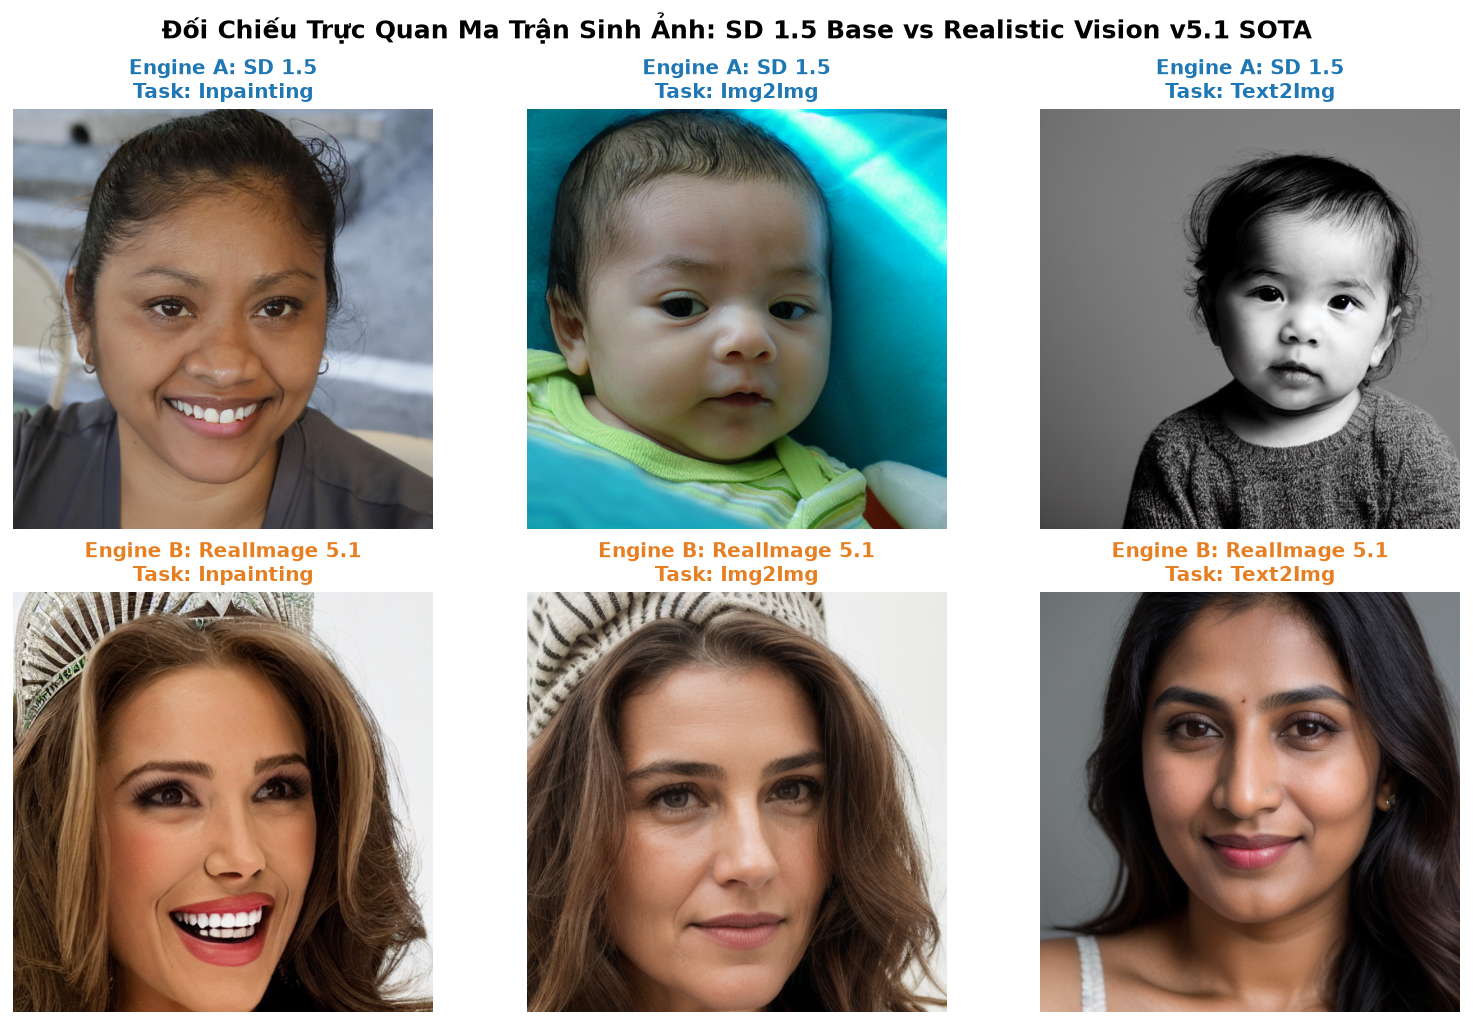

In [4]:
# Trực quan hóa ma trận 2x3 đối chứng 2 engine sinh ảnh
plt.show()


### 4. Quy Trình Sinh Ảnh Ngoại Miền Chuyên Nghiệp Trên Kaggle GPU (Realistic Vision v5.1 Pipeline)

Bộ sinh Engine B được tạo độc lập trên GPU thông qua Notebook [`generator_realistic_vision_kaggle.ipynb`](generator_realistic_vision_kaggle.ipynb):
- **Foundation Model**: `SG161222/Realistic_Vision_V5.1_noVAE` nạp ở chế độ `fp16` nhằm tối ưu VRAM GPU T4/P100.
- **Negative Prompt Matrix**: Loại bỏ triệt để các biến dạng cơ thể và khuôn mặt kỳ dị:
  > `"(deformed, distorted, disfigured:1.3), poorly drawn, bad anatomy, wrong anatomy, extra limb, missing limb, floating limbs, (mutated hands and fingers:1.4), disconnected limbs, mutation, mutated, ugly, disgusting, blurry, amputation"`
- **Kỹ thuật Mặt nạ Landmark Mềm (Feathered Bounding Mask)**:
  - *Vùng miệng*: Tọa độ tương đối $[0.35, 0.65] \times [0.65, 0.90]$.
  - *Vùng mắt*: Tọa độ tương đối $[0.15, 0.85] \times [0.20, 0.50]$.
  - *Làm mờ biên (Gaussian Feathering Blur $k=21$)*: Giúp ảnh inpaint hòa quyện hoàn hảo vào ảnh gốc, loại trừ hoàn toàn các đường cắt ghép sắc nhọn (seam boundary artifacts).


### 5. Ý Nghĩa Khoa Học Của Chiến Lược Dữ Liệu Kép (Scientific Takeaway)

1. **Chống Học Vẹt Tần Số (Anti-Shortcut Learning)**:
   - Các detector thông thường rất dễ bị overfit vào vết sọc đặc trưng của bộ giải mã VAE trên SD 1.5.
   - Việc lưu giữ trọn vẹn 6.000 ảnh RealImage v5.1 làm **Kho kiểm định mù (Blind Test Vault)** giúp kiểm chứng khách quan xem mô hình có thực sự học được bản chất dị thường sinh học hay chỉ đơn thuần ghi nhớ Fourier footprint của SD 1.5.
2. **Minh Chứng Vượt Trội Của Active Learning**:
   - Khi kiểm định trên 6.000 ảnh RealImage v5.1 ([Notebook 05](05_synthetic_face_6k_realimage_benchmark.ipynb)), mô hình $M_2^*$ đạt **$70.13\%$ Fake Recall** (so với chỉ $2.00\%$ của Baseline $M_0$).
   - Đây là bằng chứng thực nghiệm rõ ràng nhất cho thấy: **Việc khai thác mẫu khó trên SD 1.5 đã giúp mô hình tự trang bị khả năng tổng quát hóa xuyên bộ sinh (Cross-Generator Generalization) một cách ngoạn mục!**
